In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [25]:
df = pd.read_csv(
    "volvedatacsv.csv",
    encoding="latin1"
)

df["DATEPRD"] = pd.to_datetime(
    df["DATEPRD"],
    format="%d-%b-%y"
)

print(df.shape)

(15634, 24)


In [26]:
prod_cols = [
    "BORE_OIL_VOL",
    "BORE_WAT_VOL",
    "BORE_GAS_VOL"
]

for col in prod_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

In [27]:
# Conversion Factors

SM3_TO_BBL = 6.2898
SM3_TO_SCF = 35.3147

# Oil

df["OIL_BOPD"] = (
    df["BORE_OIL_VOL"] * SM3_TO_BBL
)

# Water

df["WATER_BWPD"] = (
    df["BORE_WAT_VOL"] * SM3_TO_BBL
)

# Gas

df["GAS_MMSCFD"] = (
    df["BORE_GAS_VOL"]
    * SM3_TO_SCF
    / 1_000_000
)

# Water Cut

df["WC"] = (
    df["BORE_WAT_VOL"]
    /
    (
        df["BORE_OIL_VOL"]
        +
        df["BORE_WAT_VOL"]
    )
) * 100

df["WC"] = df["WC"].fillna(0)

# GOR

df["GOR_SCF_STB"] = (
    (df["BORE_GAS_VOL"] * SM3_TO_SCF)
    /
    (df["BORE_OIL_VOL"] * SM3_TO_BBL)
)

df["GOR_SCF_STB"] = (
    df["GOR_SCF_STB"]
    .replace([np.inf,-np.inf],np.nan)
    .fillna(0)
)

BAR_TO_PSI = 14.5038

df["DHP_PSI"] = (
    df["AVG_DOWNHOLE_PRESSURE"]
    * BAR_TO_PSI
)

In [28]:
well_list = sorted(
    df["NPD_WELL_BORE_NAME"]
    .dropna()
    .unique()
)

for i, well in enumerate(well_list):
    print(i, well)

0 15/9-F-1 C
1 15/9-F-11
2 15/9-F-12
3 15/9-F-14
4 15/9-F-15 D
5 15/9-F-4
6 15/9-F-5


In [29]:
well_name = "15/9-F-1 C"

In [30]:
well = (
    df[
        df["NPD_WELL_BORE_NAME"]
        == well_name
    ]
    .copy()
)

well = well.sort_values(
    "DATEPRD"
)


In [31]:
cum_oil = (
    well["OIL_BOPD"].sum()
)

cum_water = (
    well["WATER_BWPD"].sum()
)

cum_gas = (
    well["GAS_MMSCFD"].sum()
)

peak_oil = (
    well["OIL_BOPD"].max()
)

peak_water = (
    well["WATER_BWPD"].max()
)

peak_gas = (
    well["GAS_MMSCFD"].max()
)

current_wc = (
    well["WC"].iloc[-1]
)

current_gor = (
    well["GOR_SCF_STB"].iloc[-1]
)

print("="*50)
print("PRODUCTION SUMMARY")
print("="*50)

print(f"Well          : {well_name}")

print(f"Peak Oil      : {peak_oil:,.0f} BOPD")

print(f"Peak Water    : {peak_water:,.0f} BWPD")

print(f"Peak Gas      : {peak_gas:.2f} MMSCFD")

print(f"Current WC    : {current_wc:.1f} %")

print(f"Current GOR   : {current_gor:.0f} scf/stb")

PRODUCTION SUMMARY
Well          : 15/9-F-1 C
Peak Oil      : 6,101 BOPD
Peak Water    : 6,233 BWPD
Peak Gas      : 0.02 MMSCFD
Current WC    : 0.0 %
Current GOR   : 0 scf/stb


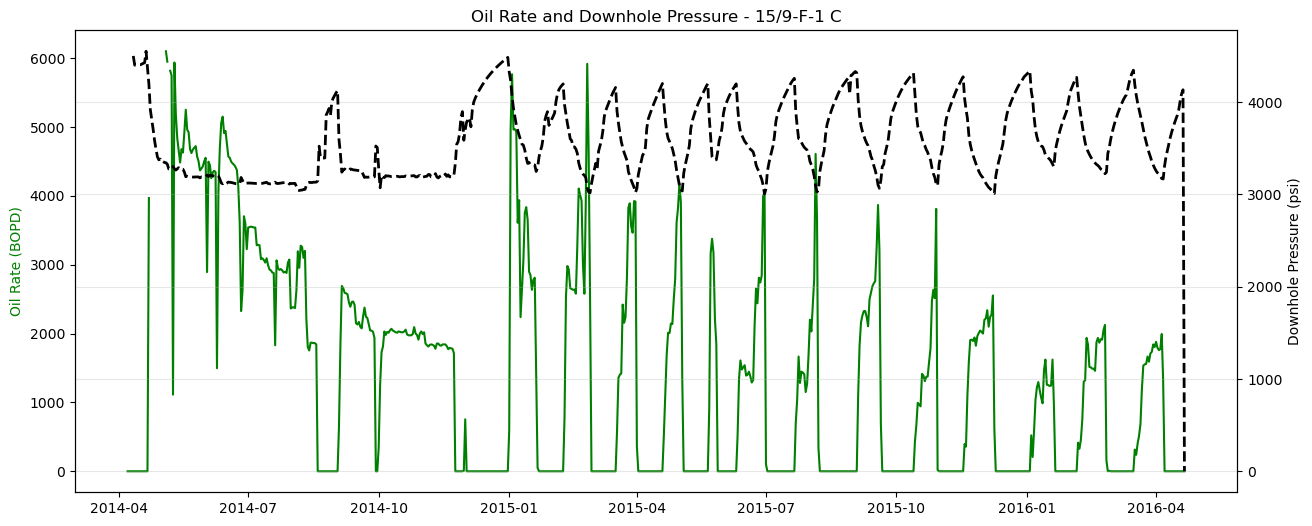

In [35]:
fig, ax1 = plt.subplots(figsize=(15,6))

# Oil Rate

ax1.plot(
    well["DATEPRD"],
    well["OIL_BOPD"],
    color="green",
    label="Oil Rate"
)

ax1.set_ylabel(
    "Oil Rate (BOPD)",
    color="green"
)

# Pressure

ax2 = ax1.twinx()

ax2.plot(
    well["DATEPRD"],
    well["DHP_PSI"],
    color="black",
    linestyle="--",
    linewidth=2,
    label="Downhole Pressure"
)

ax2.set_ylabel(
    "Downhole Pressure (psi)",
    color="black"
)

plt.title(
    f"Oil Rate and Downhole Pressure - {well_name}"
)

plt.grid(True, alpha=0.3)

plt.show()

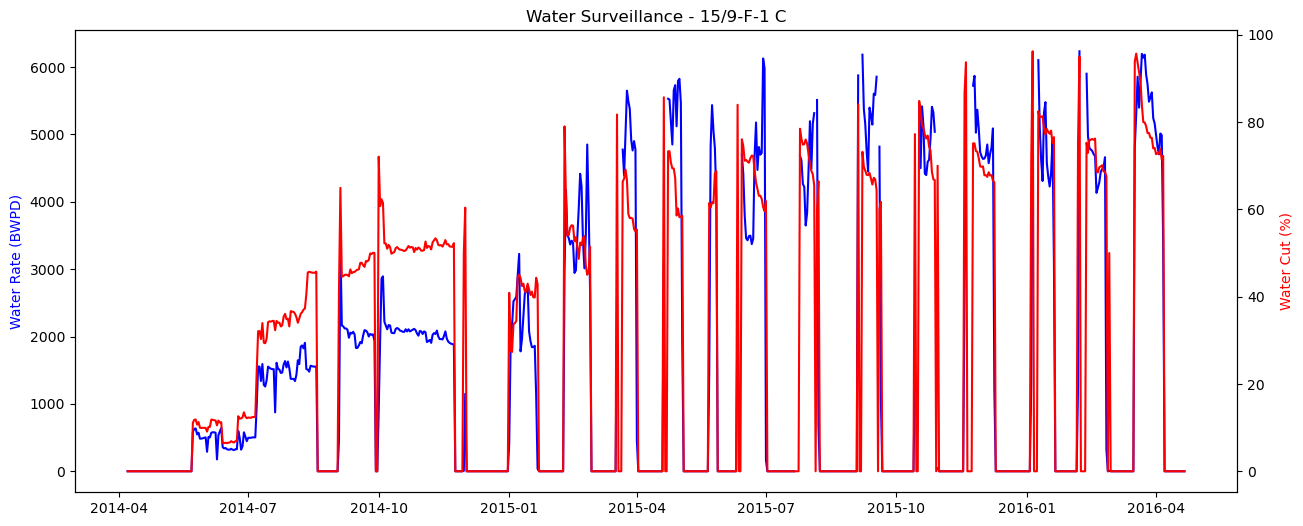

In [33]:
fig, ax1 = plt.subplots(
    figsize=(15,6)
)

ax1.plot(
    well["DATEPRD"],
    well["WATER_BWPD"],
    color="blue"
)

ax1.set_ylabel(
    "Water Rate (BWPD)",
    color="blue"
)

ax2 = ax1.twinx()

ax2.plot(
    well["DATEPRD"],
    well["WC"],
    color="red"
)

ax2.set_ylabel(
    "Water Cut (%)",
    color="red"
)

plt.title(
    f"Water Surveillance - {well_name}"
)

plt.show()

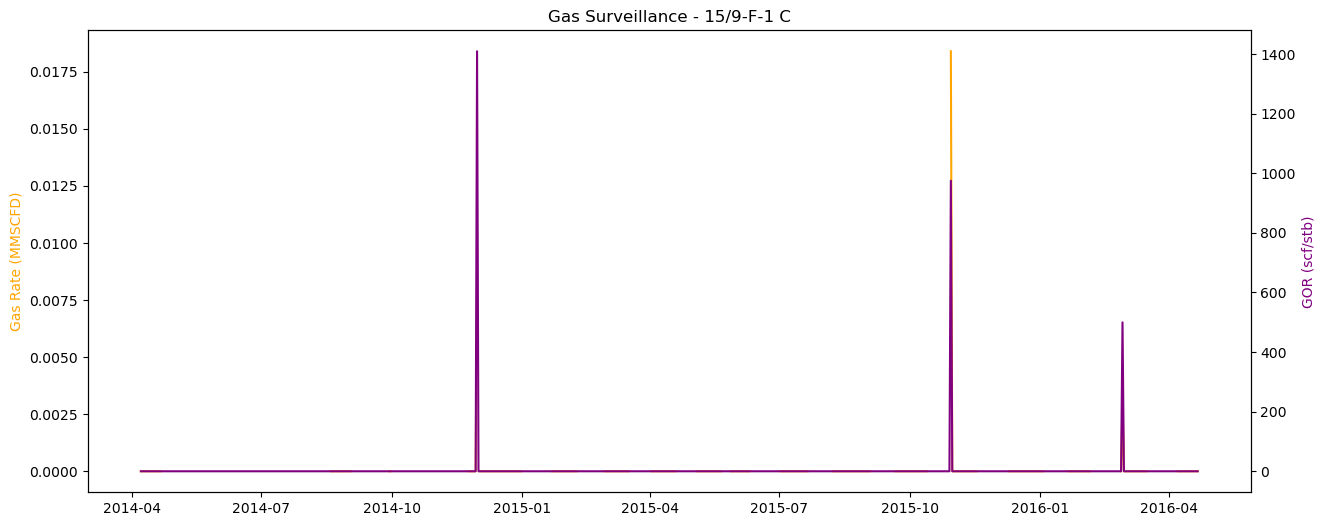

In [34]:
fig, ax1 = plt.subplots(
    figsize=(15,6)
)

ax1.plot(
    well["DATEPRD"],
    well["GAS_MMSCFD"],
    color="orange"
)

ax1.set_ylabel(
    "Gas Rate (MMSCFD)",
    color="orange"
)

ax2 = ax1.twinx()

ax2.plot(
    well["DATEPRD"],
    well["GOR_SCF_STB"],
    color="purple"
)

ax2.set_ylabel(
    "GOR (scf/stb)",
    color="purple"
)

plt.title(
    f"Gas Surveillance - {well_name}"
)

plt.show()

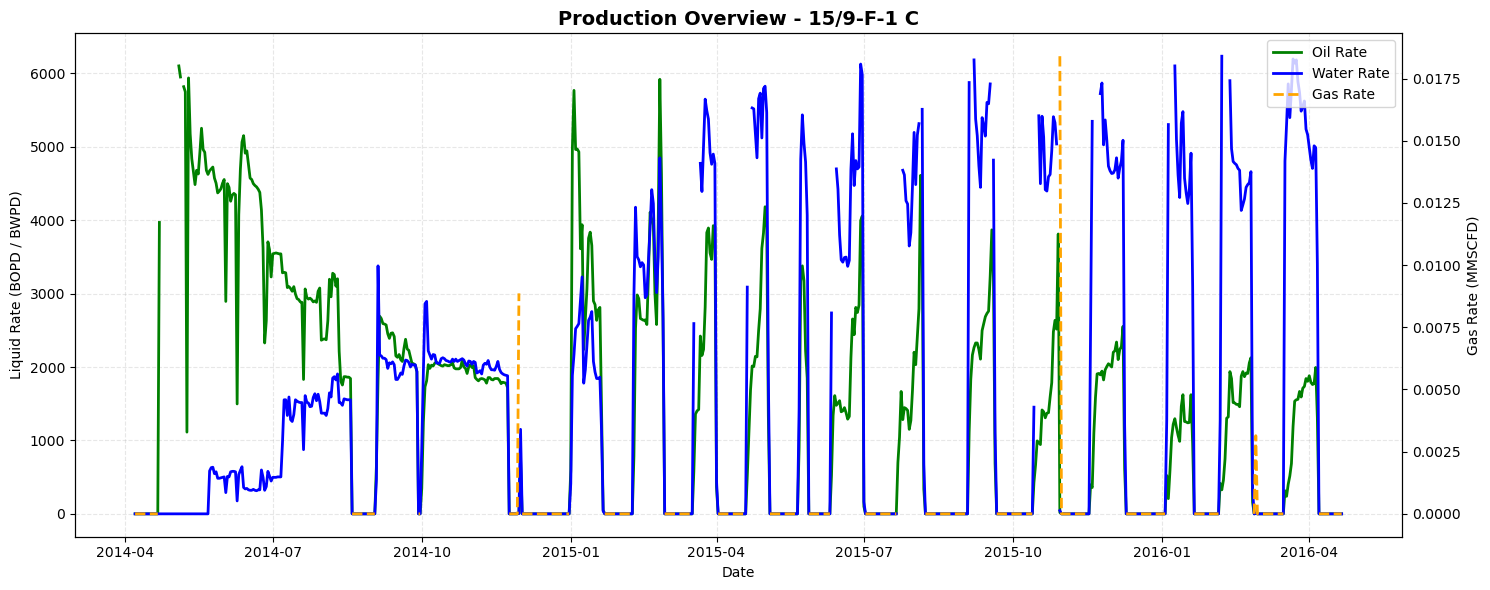

In [36]:
fig, ax1 = plt.subplots(figsize=(15,6))

# Oil Rate

ax1.plot(
    well["DATEPRD"],
    well["OIL_BOPD"],
    color="green",
    linewidth=2,
    label="Oil Rate"
)

# Water Rate

ax1.plot(
    well["DATEPRD"],
    well["WATER_BWPD"],
    color="blue",
    linewidth=2,
    label="Water Rate"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Liquid Rate (BOPD / BWPD)")

# Gas Rate on Secondary Axis

ax2 = ax1.twinx()

ax2.plot(
    well["DATEPRD"],
    well["GAS_MMSCFD"],
    color="orange",
    linewidth=2,
    linestyle="--",
    label="Gas Rate"
)

ax2.set_ylabel("Gas Rate (MMSCFD)")

# Combined Legend

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

plt.title(
    f"Production Overview - {well_name}",
    fontsize=14,
    fontweight="bold"
)

ax1.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()